# Fine-tuned Chatbot Tim Legal berbasis RAG


---
## 1. Setup & Instalasi Dependensi

In [1]:
%%capture
# Instalasi Unsloth dan library yang dibutuhkan
!pip install unsloth
!pip install --force-reinstall --no-cache-dir --no-deps unsloth
!pip install trl transformers datasets accelerate bitsandbytes peft matplotlib

In [2]:
import torch
import os
import matplotlib.pyplot as plt

# Verifikasi GPU
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

CUDA Available: True
Device Name: Tesla T4
VRAM: 15.64 GB


---
## 2. Autentikasi Hugging Face (Environment Variable)

In [3]:
# Memuat Hugging Face Token dari Kaggle Secrets
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    secrets = UserSecretsClient()
    hf_token = secrets.get_secret("HF_TOKEN")
    os.environ["HF_TOKEN"] = hf_token
    login(token=hf_token)
    print("Berhasil login ke Hugging Face via Kaggle Secrets!")
except Exception as e:
    print(f"Gagal memuat secret via Kaggle Secrets: {e}")
    print("Pastikan Add-ons > Secrets > HF_TOKEN sudah ditambahkan di notebook Kaggle Anda.")

HF_USERNAME = "afihsan"
REPO_NAME_SFT = f"{HF_USERNAME}/qwen2.5-1.5b-legal-chatbot-finetuned"

print(f"Target Repositori SFT: https://huggingface.co/{REPO_NAME_SFT}")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Berhasil login ke Hugging Face via Kaggle Secrets!
Target Repositori SFT: https://huggingface.co/afihsan/qwen2.5-1.5b-legal-chatbot-finetuned


---
## 3. Memuat Pre-trained Model & Konfigurasi QLoRA 4-bit

Model yang digunakan adalah `unsloth/Qwen2.5-1.5B` dengan kuantisasi 4-bit (QLoRA double quantization).
Adapter LoRA diterapkan pada komponen komputasi utama:
- **Multi-Head Attention**: `q_proj`, `k_proj`, `v_proj`, `o_proj`
- **Feed Forward Network (FFN)**: `gate_proj`, `up_proj`, `down_proj`

In [4]:
from unsloth import FastLanguageModel

max_seq_length = 2048
dtype = None 
load_in_4bit = True

# 1. Load Pre-trained Base Model
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B",
    max_seq_length=max_seq_length,
    dtype=dtype,
    load_in_4bit=load_in_4bit,
)

# 2. Konfigurasi LoRA Adapter pada Multi-Head Attention & FFN
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",      # Multi-Head Attention
        "gate_proj", "up_proj", "down_proj",        # Feed Forward Network (FFN)
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
    use_rslora=False,
    loftq_config=None,
)

print("Model dan LoRA adapter berhasil diinisialisasi!")
model.print_trainable_parameters()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.7: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
total weights      : 1.291 GiB
no_split classes   : ['Qwen2DecoderLayer']
output head        : lm_head -> cuda:1
head headroom      : 0.359 GiB
activation reserve : 12.149 GiB requested
tied to head       : ['model.embed_tokens']
  cuda:0  budget  12.95 GiB  weights  0.755 GiB  free 12.197 GiB  reserve 12.149 GiB
  cuda:1  budget  13.00 GiB  weights  0.536 GiB  free 12.460 GiB  reserve 11.992 GiB   <- output 

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth 2026.9.7 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Model dan LoRA adapter berhasil diinisialisasi!
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


---
## 4. Persiapan Dataset, ChatML Mapping, & Train/Val Split

Sesuai ketentuan:
1. Dataset mentah `Ichsan2895/alpaca-gpt4-indonesian` di-load via Hugging Face `datasets`.
2. Menampilkan 1 baris dataset **SEBELUM** mapping.
3. Menggunakan fungsi mapping untuk mengubah ke format **ChatML**.
4. Menampilkan 1 baris dataset **SETELAH** mapping lengkap dengan special token.
5. **Skilled**: Membagi dataset menjadi `train_dataset` (90%) dan `eval_dataset` (10%).

In [5]:
from datasets import load_dataset
from unsloth.chat_templates import get_chat_template

# 1. Load dataset
print("Mengunduh dataset...")
raw_dataset = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train")
print(f"Total data mentah: {len(raw_dataset)} baris\n")

# 2. Tampilkan contoh data SEBELUM mapping (Menggunakan kolom input dan output)
print('=' * 60)
print('CONTOH DATA SEBELUM MAPPING (RAW):')
print('=' * 60)
sample_raw = raw_dataset[0]
print(f"Kolom dataset : {raw_dataset.column_names}")
print(f"Input         : {sample_raw.get('input', '')}")
print(f"Output        : {sample_raw.get('output', '')}\n")

# 3. Setup ChatML Template pada tokenizer
tokenizer = get_chat_template(
    tokenizer,
    chat_template='chatml',
)

# 4. Fungsi mapping ke ChatML (kolom pertanyaan ada di 'input')
def format_to_chatml(example):
    user_content = (example.get('input') or example.get('instruction', '')).strip()
    assistant_content = example.get('output', '').strip()
    return {
        'conversations': [
            {'role': 'user', 'content': user_content},
            {'role': 'assistant', 'content': assistant_content}
        ]
    }

dataset_mapped = raw_dataset.map(format_to_chatml, desc="Mapping ke ChatML")

# Buat kolom 'text' terformat menggunakan chat template
def apply_template(example):
    text = tokenizer.apply_chat_template(
        example["conversations"],
        tokenize=False,
        add_generation_prompt=False,
    )
    return {"text": text}

dataset_formatted = dataset_mapped.map(apply_template, desc="Mengaplikasikan Chat Template")

# 5. Tampilkan contoh data SETELAH mapping lengkap dengan special token
print("=" * 60)
print("CONTOH DATA SETELAH MAPPING (CHATML LENGKAP DENGAN SPECIAL TOKENS):")
print("=" * 60)
print(dataset_formatted[0]["text"][:600])
print("=" * 60)


Mengunduh dataset...


README.md: 0.00B [00:00, ?B/s]

alpaca-gpt4-indonesia.csv:   0%|          | 0.00/41.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

[unsloth.chat_templates|WARNING]Unsloth: Will map <|im_end|> to EOS = <|endoftext|>.


Total data mentah: 49969 baris

CONTOH DATA SEBELUM MAPPING (RAW):
Kolom dataset : ['Unnamed: 0', 'input', 'output']
Input         : Saranlah slogan untuk kampanye daur ulang

Output        : 1. "Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau."
2. "Daur ulanglah hari ini, untuk masa depan yang lebih baik."
3. "Ubah sampahmu menjadi harta karun - Daur ulang!"
4. "Daur ulang untuk siklus kehidupan."
5. "Simpan sumber daya, daur ulang lebih banyak."



Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/_unsloth_sentencepiece_temp/tokenizer_9gjyj0ep/tokenizer_config.json.


Mapping ke ChatML:   0%|          | 0/49969 [00:00<?, ? examples/s]

Mengaplikasikan Chat Template:   0%|          | 0/49969 [00:00<?, ? examples/s]

CONTOH DATA SETELAH MAPPING (CHATML LENGKAP DENGAN SPECIAL TOKENS):
<|im_start|>user
Saranlah slogan untuk kampanye daur ulang<|im_end|>
<|im_start|>assistant
1. "Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau."
2. "Daur ulanglah hari ini, untuk masa depan yang lebih baik."
3. "Ubah sampahmu menjadi harta karun - Daur ulang!"
4. "Daur ulang untuk siklus kehidupan."
5. "Simpan sumber daya, daur ulang lebih banyak."<|im_end|>



In [6]:
# 6. Train / Validation Split
split_dataset = dataset_formatted.train_test_split(test_size=0.10, seed=3407)
train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

print(f"Pembagian dataset berhasil:")
print(f"   - Training Set   : {len(train_dataset)} baris (90%)")
print(f"   - Validation Set : {len(eval_dataset)} baris (10%)")

Pembagian dataset berhasil:
   - Training Set   : 44972 baris (90%)
   - Validation Set : 4997 baris (10%)


---
## 5. Eksperimen Fine-Tuning & Analisis Kurva Loss

- Modifikasi `TrainingArguments` dengan `eval_dataset`, `eval_strategy='steps'`, dan `logging_steps`.
- Melakukan **setidaknya 2 kali eksperimen** dengan variasi hyperparameter:
  - **Eksperimen 1**: Baseline — Learning Rate `2e-4`, LoRA `r=16`, `alpha=16`.
  - **Eksperimen 2**: Alternatif — Learning Rate `1e-4` (lebih konservatif), LoRA `r=32`, `alpha=32`, `weight_decay=0.05`.
- Visualisasi grafik Training Loss vs Validation Loss dari kedua percobaan untuk menganalisis konvergensi dan mencegah overfitting.

In [7]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# EKSPERIMEN 1: Baseline (LR=2e-4, LoRA r=16, steps=800)
print("Menjalankan Konfigurasi SFTTrainer Eksperimen 1...")

args_exp1 = TrainingArguments(
    output_dir="outputs_exp1",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    warmup_steps=20,
    max_steps=800,
    learning_rate=2e-4,
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),
    logging_steps=10,
    logging_dir="./logs_exp1",
    eval_strategy="steps",
    eval_steps=100,
    optim="adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="linear",
    seed=3407,
    report_to="none",
)

trainer_exp1 = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    dataset_text_field="text",
    max_seq_length=2048,
    dataset_num_proc=2,
    packing=False,
    args=args_exp1,
)

print("Mulai training Eksperimen 1 (800 steps)...")
trainer_stats_exp1 = trainer_exp1.train()
print("Eksperimen 1 selesai!")

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Menjalankan Konfigurasi SFTTrainer Eksperimen 1...


`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/44972 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/4997 [00:00<?, ? examples/s]

...

/usr/local/lib/python3.12/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.12/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.12/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.12/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_mkldnn' is deprecated, please use 'torch.backends.mkldnn.is_available()'
  return original(name)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,1.462972,1.485770
200,1.444558,1.457515
300,1.346005,1.441568
400,1.484472,1.429305
500,1.407811,1.419827
600,1.373773,1.412449
700,1.393423,1.407538
800,1.372679,1.405049


Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-800/tokenizer_config.json.


Eksperimen 1 selesai!


In [8]:
# EKSPERIMEN 2: Alternatif Hyperparameter
# Variasi: LR=1e-4, LoRA r=32, weight_decay=0.05
print("Menjalankan Konfigurasi SFTTrainer Eksperimen 2 (Variasi Hyperparameter)...\n")

# Reset model LoRA dengan rank=32
model_exp2, tokenizer_exp2 = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B",
    max_seq_length=2048,
    dtype=dtype,
    load_in_4bit=load_in_4bit,
)

model_exp2 = FastLanguageModel.get_peft_model(
    model_exp2,
    r=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=32,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

args_exp2 = TrainingArguments(
    output_dir="outputs_exp2",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    warmup_steps=20,
    max_steps=800,
    learning_rate=1e-4,
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),
    logging_steps=10,
    logging_dir="./logs_exp2",
    eval_strategy="steps",
    eval_steps=100,
    optim="adamw_8bit",
    weight_decay=0.05,
    lr_scheduler_type="cosine",
    seed=3407,
    report_to="none",
)

trainer_exp2 = SFTTrainer(
    model=model_exp2,
    tokenizer=tokenizer_exp2,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    dataset_text_field="text",
    max_seq_length=2048,
    dataset_num_proc=2,
    packing=False,
    args=args_exp2,
)

print("Mulai training Eksperimen 2 (800 steps)...\n")
trainer_stats_exp2 = trainer_exp2.train()
print("Eksperimen 2 selesai!")

Menjalankan Konfigurasi SFTTrainer Eksperimen 2 (Variasi Hyperparameter)...

==((====))==  Unsloth 2026.9.7: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
total weights      : 1.291 GiB
no_split classes   : ['Qwen2DecoderLayer']
output head        : lm_head -> cuda:1
head headroom      : 0.359 GiB
activation reserve : 11.359 GiB requested
tied to head       : ['model.embed_tokens']
  cuda:0  budget  12.02 GiB  weights  0.646 GiB  free 11.369 GiB  reserve 11.359 GiB
  cuda:1  budget  12.35 GiB  weights  0.645 GiB  free 11.708 GiB  reserve 11.349 GiB   <- output head
note: Bnb4BitHfQuantizer.adjust_max_memory lowered the b

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/44972 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/4997 [00:00<?, ? examples/s]

...

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 2
   \\   /|    Num examples = 44,972 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 36,929,536 of 1,580,643,840 (2.34% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,1.550527,1.600419
200,1.537351,1.568214
300,1.431775,1.550011
400,1.582138,1.537219
500,1.511482,1.527339
600,1.478765,1.521287
700,1.474527,1.518074
800,1.459574,1.517613


Unsloth: Restored added_tokens_decoder metadata in outputs_exp2/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_exp2/checkpoint-800/tokenizer_config.json.


Eksperimen 2 selesai!


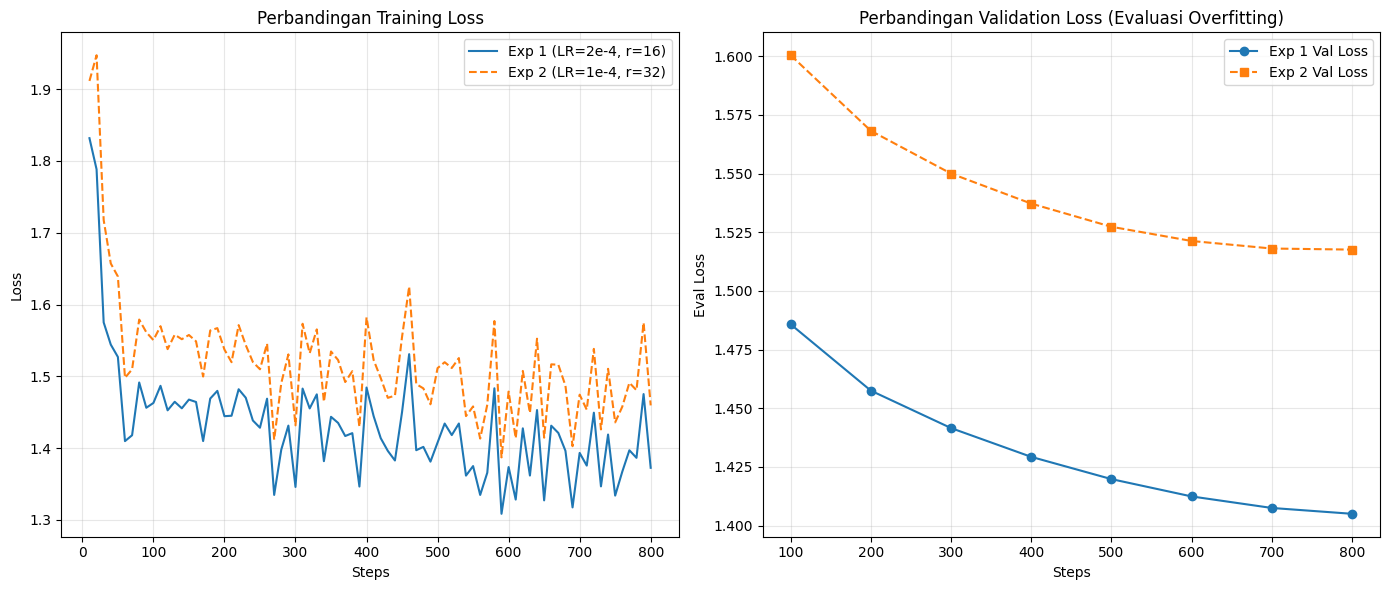

Analisis Hasil:
- Eksperimen dengan validation loss terendah dan kurva paling stabil dipilih sebagai model terbaik.


In [9]:
# Visualisasi dan Perbandingan Kurva Loss Kedua Eksperimen
def extract_loss_logs(log_history):
    train_steps, train_loss = [], []
    eval_steps, eval_loss = [], []
    for log in log_history:
        if "loss" in log and "step" in log:
            train_steps.append(log["step"])
            train_loss.append(log["loss"])
        if "eval_loss" in log and "step" in log:
            eval_steps.append(log["step"])
            eval_loss.append(log["eval_loss"])
    return train_steps, train_loss, eval_steps, eval_loss

t_steps1, t_loss1, e_steps1, e_loss1 = extract_loss_logs(trainer_exp1.state.log_history)
t_steps2, t_loss2, e_steps2, e_loss2 = extract_loss_logs(trainer_exp2.state.log_history)

plt.figure(figsize=(14, 6))

# Subplot 1: Training Loss
plt.subplot(1, 2, 1)
if t_steps1 and t_loss1:
    plt.plot(t_steps1, t_loss1, label="Exp 1 (LR=2e-4, r=16)", color="#1f77b4")
if t_steps2 and t_loss2:
    plt.plot(t_steps2, t_loss2, label="Exp 2 (LR=1e-4, r=32)", color="#ff7f0e", linestyle="--")
plt.title("Perbandingan Training Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Validation Loss
plt.subplot(1, 2, 2)
if e_steps1 and e_loss1:
    plt.plot(e_steps1, e_loss1, label="Exp 1 Val Loss", color="#1f77b4", marker="o")
if e_steps2 and e_loss2:
    plt.plot(e_steps2, e_loss2, label="Exp 2 Val Loss", color="#ff7f0e", marker="s", linestyle="--")
plt.title("Perbandingan Validation Loss (Evaluasi Overfitting)")
plt.xlabel("Steps")
plt.ylabel("Eval Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Analisis Hasil:")
print("- Eksperimen dengan validation loss terendah dan kurva paling stabil dipilih sebagai model terbaik.")

In [10]:
# Unggah Model SFT Terbaik ke Hugging Face
print(f"Mengunggah Base SFT Model ke Hugging Face: {REPO_NAME_SFT}")

# Model Eksperimen 1 bernama 'model', Eksperimen 2 bernama 'model_exp2'
model_exp1 = model

best_model = model_exp1 if (e_loss1 and e_loss2 and e_loss1[-1] <= e_loss2[-1]) else model_exp2
best_tokenizer = tokenizer if best_model == model_exp1 else tokenizer_exp2

print("Memulai proses merge & upload ke Hugging Face...")
best_model.push_to_hub_merged(
    REPO_NAME_SFT,
    best_tokenizer,
    save_method="merged_16bit",
    token=os.environ["HF_TOKEN"],
)

print(f"Model SFT berhasil diunggah: https://huggingface.co/{REPO_NAME_SFT}")
print("Model ini siap digunakan untuk GRPO di notebook GRPO_submission_PGABL_Nama-siswa.ipynb!")


Mengunggah Base SFT Model ke Hugging Face: afihsan/qwen2.5-1.5b-legal-chatbot-finetuned
Memulai proses merge & upload ke Hugging Face...


config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.
Unsloth: Restored added_tokens_decoder metadata in afihsan/qwen2.5-1.5b-legal-chatbot-finetuned/tokenizer_config.json.


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

...

Unsloth: Merging weights into 16bit:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:48<00:00, 48.04s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/afihsan/qwen2.5-1.5b-legal-chatbot-finetuned`
Model SFT berhasil diunggah: https://huggingface.co/afihsan/qwen2.5-1.5b-legal-chatbot-finetuned
Model ini siap digunakan untuk GRPO di notebook GRPO_submission_PGABL_Nama-siswa.ipynb!
